<a href="https://colab.research.google.com/github/Godson2105/ELECTION_DATA-ANALYSIS/blob/main/IR_TASK_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving News_Category_Dataset_v3.json to News_Category_Dataset_v3.json


In [ ]:
import pandas as pd
import numpy as np
import json
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import os

filename = next(
    (f for f in uploaded if f.endswith(".json")),
    None
)

if filename is None:
    raise ValueError("Please upload the JSON dataset.")

df = pd.read_json(filename, lines=True)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset shape: (209527, 6)

Column names:
['link', 'headline', 'category', 'short_description', 'authors', 'date']

First five records:


,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [ ]:
import os

filename = next(
    (f for f in uploaded if f.endswith(".json")),
    None
)

if filename is None:
    raise ValueError("Please upload the JSON dataset.")

df = pd.read_json(filename, lines=True)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Dataset shape: (209527, 6)

Column names:
['link', 'headline', 'category', 'short_description', 'authors', 'date']

First five records:


,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [ ]:
categories = [
    "POLITICS",
    "WELLNESS",
    "ENTERTAINMENT",
    "TRAVEL",
    "STYLE & BEAUTY",
    "PARENTING"
]

df = df.dropna(subset=["category", "headline"]).copy()

df["text"] = (
    df["headline"].fillna("").astype(str) + " " +
    df["short_description"].fillna("").astype(str)
).str.strip()

df = df[df["category"].isin(categories)]
df = df[df["text"].str.len() > 0]

df = df.drop_duplicates(subset=["text", "category"])

df = df.sample(
    n=min(10000, len(df)),
    random_state=42
).reset_index(drop=True)

print("Number of documents:", len(df))
print("Number of classes:", df["category"].nunique())

print("\nClass distribution:")
print(df["category"].value_counts())

print("\nPercentage distribution:")
print((df["category"].value_counts(normalize=True) * 100).round(2))

Number of documents: 10000
Number of classes: 6

Class distribution:
category
POLITICS          3693
ENTERTAINMENT     1771
WELLNESS          1740
STYLE & BEAUTY     964
TRAVEL             952
PARENTING          880
Name: count, dtype: int64

Percentage distribution:
category
POLITICS          36.93
ENTERTAINMENT     17.71
WELLNESS          17.40
STYLE & BEAUTY     9.64
TRAVEL             9.52
PARENTING          8.80
Name: proportion, dtype: float64


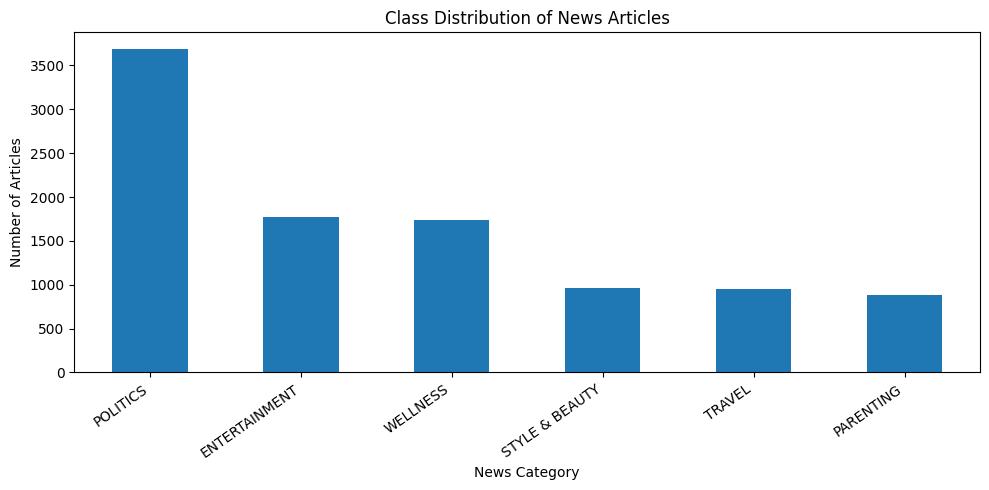

In [ ]:
counts = df["category"].value_counts()

plt.figure(figsize=(10, 5))
counts.plot(kind="bar")
plt.title("Class Distribution of News Articles")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
X = df["text"]
y = df["category"]

xtrain, xtest, ytrain, ytest = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english",
    max_features=15000,
    ngram_range=(1, 2),
    sublinear_tf=True
)

xtrain = vectorizer.fit_transform(xtrain)
xtest = vectorizer.transform(xtest)

print("Training documents:", xtrain.shape[0])
print("Testing documents:", xtest.shape[0])
print("Number of TF-IDF features:", xtrain.shape[1])
print("Training feature matrix:", xtrain.shape)
print("Testing feature matrix:", xtest.shape)

Training documents: 8000
Testing documents: 2000
Number of TF-IDF features: 15000
Training feature matrix: (8000, 15000)
Testing feature matrix: (2000, 15000)


In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=100,
        min_samples_leaf=2,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        metric="cosine",
        algorithm="brute",
        n_jobs=-1
    ),

    "SVM": LinearSVC(
        C=1.0,
        random_state=42,
        max_iter=3000
    ),

    "Naive Bayes": MultinomialNB(
        alpha=1.0
    )
}

results = []
predictions = {}

for name, model in models.items():
    start = time.time()
    model.fit(xtrain, ytrain)
    train_time = time.time() - start

    start = time.time()
    pred = model.predict(xtest)
    test_time = time.time() - start

    predictions[name] = pred

    results.append({
        "Algorithm": name,
        "Accuracy": accuracy_score(ytest, pred),
        "Precision": precision_score(
            ytest, pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            ytest, pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            ytest, pred, average="macro", zero_division=0
        ),
        "Training Time (s)": train_time,
        "Testing Time (s)": test_time,
        "Number of Features": xtrain.shape[1]
    })

    print(name, "completed")
    print("Training time:", round(train_time, 3), "seconds")
    print("Testing time:", round(test_time, 3), "seconds")
    print("-" * 40)

resultsdf = pd.DataFrame(results)

print("\nComparative Results:")
display(resultsdf.round(4))

Decision Tree completed
Training time: 1.953 seconds
Testing time: 0.002 seconds
----------------------------------------
KNN completed
Training time: 0.018 seconds
Testing time: 1.395 seconds
----------------------------------------
SVM completed
Training time: 1.247 seconds
Testing time: 0.004 seconds
----------------------------------------
Naive Bayes completed
Training time: 0.309 seconds
Testing time: 0.002 seconds
----------------------------------------

Comparative Results:


,Algorithm,Accuracy,Precision,Recall,F1-Score,Training Time (s),Testing Time (s),Number of Features
0,Decision Tree,0.6355,0.6388,0.5606,0.5863,1.9531,0.0023,15000
1,KNN,0.7405,0.7400,0.6624,0.6898,0.0178,1.3946,15000
2,SVM,0.8505,0.8416,0.8154,0.8266,1.2468,0.0043,15000
3,Naive Bayes,0.7305,0.8538,0.5987,0.6398,0.3089,0.0017,15000


In [ ]:
metrics = [
    "Algorithm",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

display(
    resultsdf[metrics]
    .sort_values("F1-Score", ascending=False)
    .round(4)
    .reset_index(drop=True)
)

,Algorithm,Accuracy,Precision,Recall,F1-Score
0,SVM,0.8505,0.8416,0.8154,0.8266
1,KNN,0.7405,0.7400,0.6624,0.6898
2,Naive Bayes,0.7305,0.8538,0.5987,0.6398
3,Decision Tree,0.6355,0.6388,0.5606,0.5863


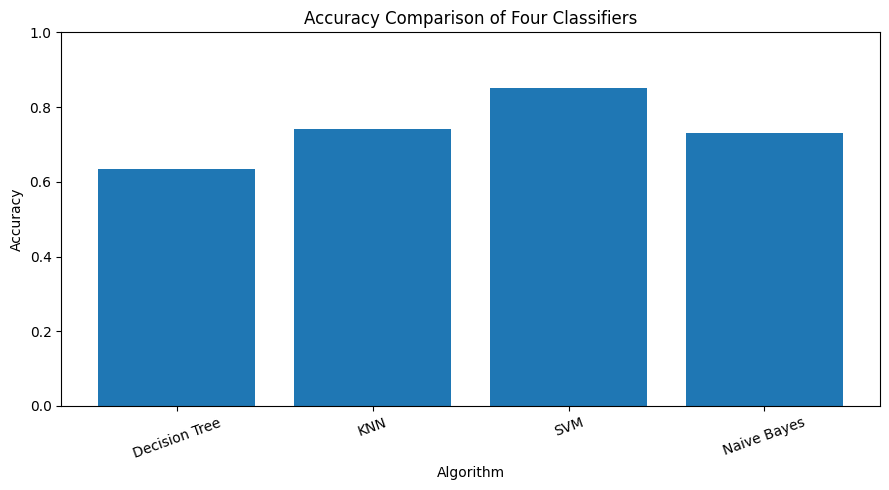

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    resultsdf["Algorithm"],
    resultsdf["Accuracy"]
)

plt.title("Accuracy Comparison of Four Classifiers")
plt.xlabel("Algorithm")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

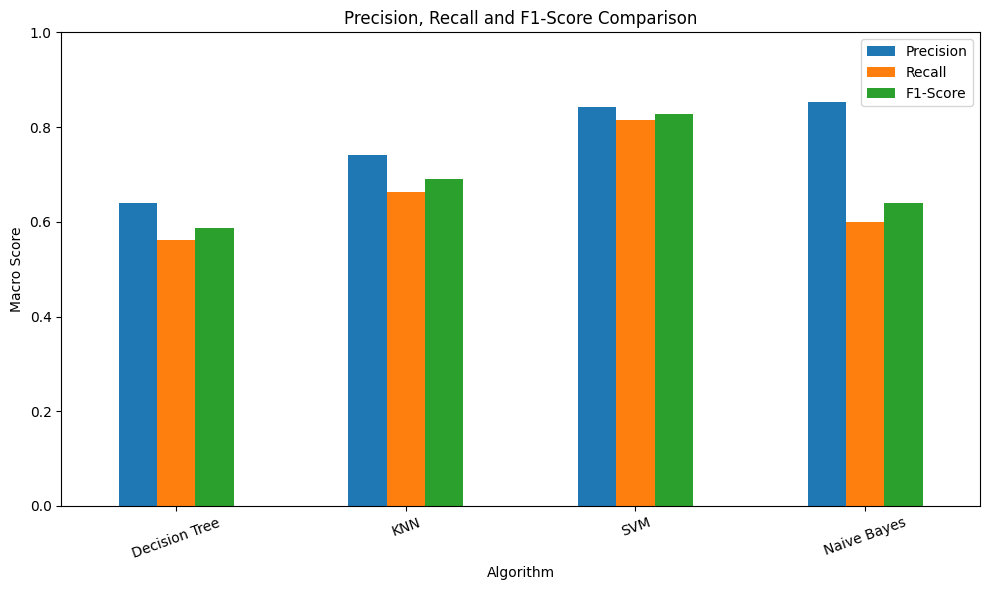

In [ ]:
resultsdf.set_index("Algorithm")[
    ["Precision", "Recall", "F1-Score"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Macro Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend()
plt.tight_layout()
plt.show()

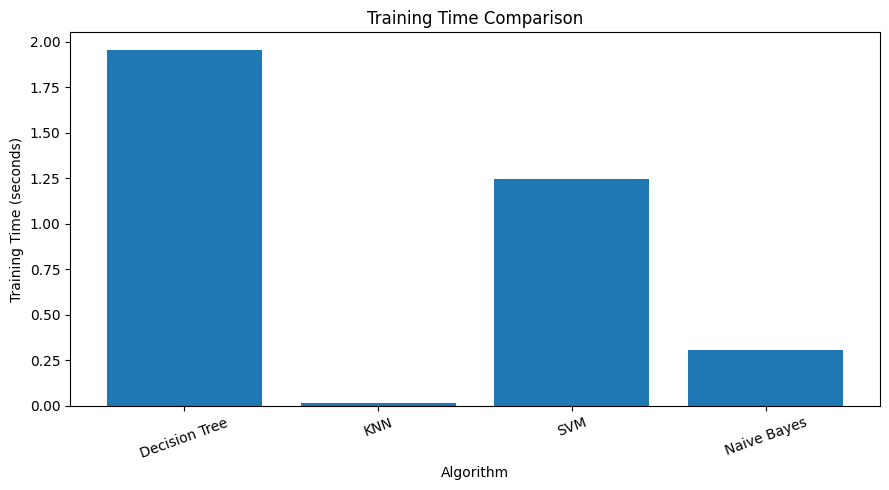

In [ ]:
plt.figure(figsize=(9, 5))

plt.bar(
    resultsdf["Algorithm"],
    resultsdf["Training Time (s)"]
)

plt.title("Training Time Comparison")
plt.xlabel("Algorithm")
plt.ylabel("Training Time (seconds)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [ ]:
bestrow = resultsdf.loc[resultsdf["F1-Score"].idxmax()]
bestname = bestrow["Algorithm"]
bestpred = predictions[bestname]

print("Best classifier:", bestname)
print("Accuracy:", round(bestrow["Accuracy"], 4))
print("Precision:", round(bestrow["Precision"], 4))
print("Recall:", round(bestrow["Recall"], 4))
print("F1-Score:", round(bestrow["F1-Score"], 4))

print("\nClassification Report:")
print(
    classification_report(
        ytest,
        bestpred,
        zero_division=0
    )
)

Best classifier: SVM
Accuracy: 0.8505
Precision: 0.8416
Recall: 0.8154
F1-Score: 0.8266

Classification Report:
                precision    recall  f1-score   support

 ENTERTAINMENT       0.83      0.76      0.80       354
     PARENTING       0.77      0.68      0.73       176
      POLITICS       0.90      0.94      0.92       739
STYLE & BEAUTY       0.88      0.85      0.87       193
        TRAVEL       0.89      0.78      0.83       190
      WELLNESS       0.77      0.88      0.82       348

      accuracy                           0.85      2000
     macro avg       0.84      0.82      0.83      2000
  weighted avg       0.85      0.85      0.85      2000



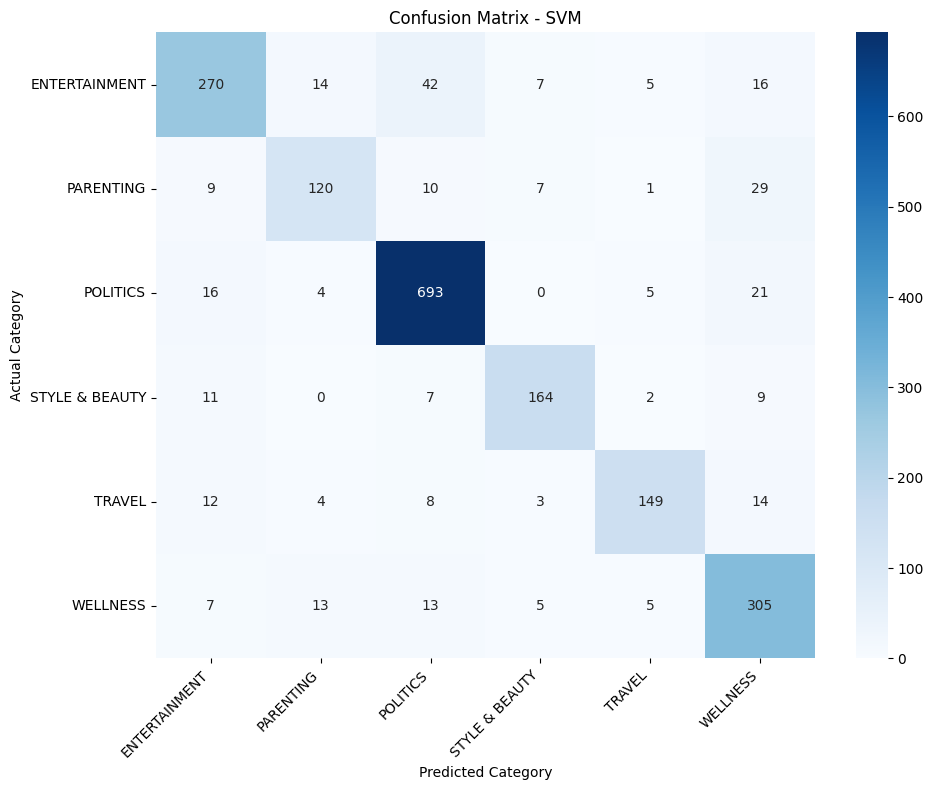

In [ ]:
cm = confusion_matrix(
    ytest,
    bestpred,
    labels=sorted(y.unique())
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sorted(y.unique()),
    yticklabels=sorted(y.unique())
)

plt.title("Confusion Matrix - " + bestname)
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
print("resultsdf exists:", "resultsdf" in globals())
print("xtrain2 exists:", "xtrain2" in globals())
print("pred2 exists:", "pred2" in globals())
print("ytest exists:", "ytest" in globals())

resultsdf exists: True
xtrain2 exists: False
pred2 exists: False
ytest exists: True


In [ ]:
vectorizer2 = TfidfVectorizer(
    max_features=5000,
    stop_words="english",
    ngram_range=(1, 2),
    sublinear_tf=True
)

xtrain2 = vectorizer2.fit_transform(
    df.loc[ytrain.index, "text"]
)

xtest2 = vectorizer2.transform(
    df.loc[ytest.index, "text"]
)

svm2 = LinearSVC(C=1.0, random_state=42, max_iter=3000)

svm2.fit(xtrain2, ytrain)
pred2 = svm2.predict(xtest2)

print("What-if experiment completed!")
print("Accuracy:", accuracy_score(ytest, pred2))
print("F1-score:", f1_score(ytest, pred2, average="macro"))

What-if experiment completed!
Accuracy: 0.8375
F1-score: 0.8100828489727738


In [ ]:
whatif = pd.DataFrame([
    {
        "TF-IDF Features": 15000,
        "Accuracy": resultsdf.loc[
            resultsdf["Algorithm"] == "SVM", "Accuracy"
        ].iloc[0],
        "Macro F1-Score": resultsdf.loc[
            resultsdf["Algorithm"] == "SVM", "F1-Score"
        ].iloc[0]
    },
    {
        "TF-IDF Features": xtrain2.shape[1],
        "Accuracy": accuracy_score(ytest, pred2),
        "Macro F1-Score": f1_score(
            ytest, pred2, average="macro"
        )
    }
])

display(whatif.round(4))

,TF-IDF Features,Accuracy,Macro F1-Score
0,15000,0.8505,0.8266
1,5000,0.8375,0.8101


In [ ]:
resultsdf.to_csv("classifier_comparison.csv", index=False)
whatif.to_csv("what_if_analysis.csv", index=False)

print("Results saved successfully.")

Results saved successfully.


In [ ]:
from google.colab import files

files.download("classifier_comparison.csv")
files.download("what_if_analysis.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>